# Vehicle Loan Default Prediction Using Machine Learning
## Course: Introduction to Artificial Intelligence (Intro to AI)
**Instructor:** Sir Ali Javed  
**Student:** Maryam Ashraf (Roll No: 2502452)  
**Research Paper:** *Vehicle Loan Default Prediction Based on Machine Learning* (Xinyue Wu, CONF-APMM 2025)  

---
### Project Overview & Deliverables
1. **Research Paper Implementation:** Complete end-to-end implementation of the data cleaning, feature engineering, and model training (Logistic Regression, Decision Tree, LightGBM, XGBoost) replicating the paper's reported results.
2. **New Addition / Novel Contribution:** Identification and resolution of the synthetic data leakage flaw (SMOTE before train-test split), cost-sensitive risk threshold calibration, and transparent feature importance analysis.

In [6]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, roc_curve
)

# Upload train.csv directly from your computer
print("Please click 'Choose Files' below and select train.csv:")
uploaded = files.upload()

# Automatically load the uploaded file
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

print(f"\nLoaded '{filename}' successfully!")
print(f"Dataset Shape: {df.shape}")
df.head()

Please click 'Choose Files' below and select train.csv:


Saving train.csv to train.csv

Loaded 'train.csv' successfully!
Dataset Shape: (233154, 41)


,UniqueID,disbursed_amount,asset_cost,ltv,branch_id,supplier_id,manufacturer_id,Current_pincode_ID,Date.of.Birth,Employment.Type,...,SEC.SANCTIONED.AMOUNT,SEC.DISBURSED.AMOUNT,PRIMARY.INSTAL.AMT,SEC.INSTAL.AMT,NEW.ACCTS.IN.LAST.SIX.MONTHS,DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS,AVERAGE.ACCT.AGE,CREDIT.HISTORY.LENGTH,NO.OF_INQUIRIES,loan_default
0,420825,50578,58400,89.55,67,22807,45,1441,01-01-84,Salaried,...,0,0,0,0,0,0,0yrs 0mon,0yrs 0mon,0,0
1,537409,47145,65550,73.23,67,22807,45,1502,31-07-85,Self employed,...,0,0,1991,0,0,1,1yrs 11mon,1yrs 11mon,0,1
2,417566,53278,61360,89.63,67,22807,45,1497,24-08-85,Self employed,...,0,0,0,0,0,0,0yrs 0mon,0yrs 0mon,0,0
3,624493,57513,66113,88.48,67,22807,45,1501,30-12-93,Self employed,...,0,0,31,0,0,0,0yrs 8mon,1yrs 3mon,1,1
4,539055,52378,60300,88.39,67,22807,45,1495,09-12-77,Self employed,...,0,0,0,0,0,0,0yrs 0mon,0yrs 0mon,1,1


## 2. Data Cleaning & Feature Engineering (Paper Section 2.2)
- Missing value imputation (Mode for categorical, Median for numerical)
- Encoding `Employment.Type` and `PERFORM_CNS.SCORE.DESCRIPTION`
- Calculating borrower `Age` from dates
- Converting credit duration strings (`"3yrs 5mon"`) into total months
- Merging Primary and Secondary account features
- Handling outliers, skewness correction, and `RobustScaler` standardization

In [7]:
# 1. Missing Value Imputation
df['Employment.Type'] = df['Employment.Type'].fillna(df['Employment.Type'].mode()[0])

# 2. Categorical Encoding
# Self employed -> 0, Salaried -> 1
df['Employment.Type'] = df['Employment.Type'].map({'Self employed': 0, 'Salaried': 1}).fillna(0).astype(int)

# Map PERFORM_CNS.SCORE.DESCRIPTION to numerical risk levels (0 to 4)
def map_cns_risk(desc):
    if pd.isna(desc):
        return 0
    d = str(desc).upper()
    if 'VERY LOW RISK' in d:
        return 4
    elif 'LOW RISK' in d:
        return 3
    elif 'MEDIUM RISK' in d:
        return 2
    elif 'HIGH RISK' in d:
        return 1
    return 0

df['PERFORM_CNS_SCORE_DESCRIPTION'] = df['PERFORM_CNS.SCORE.DESCRIPTION'].apply(map_cns_risk)

# 3. Temporal Feature: Calculate Age = DisbursalDate - Date.of.Birth
def calc_age(dob, disb):
    try:
        y = int(str(dob).split('-')[2])
        birth_year = 1900 + y if y >= 20 else 2000 + y
        disb_year = 2000 + int(str(disb).split('-')[2])
        return max(18, disb_year - birth_year)
    except:
        return 35

df['Age'] = [calc_age(dob, disb) for dob, disb in zip(df['Date.of.Birth'], df['DisbursalDate'])]

# 4. Convert Duration Strings ("3yrs 5mon") to Total Months
def parse_duration(text):
    m = re.findall(r'(\d+)yrs\s*(\d+)mon', str(text))
    return int(m[0][0]) * 12 + int(m[0][1]) if m else 0

df['AVERAGE_ACCT_AGE_MONTHS'] = df['AVERAGE.ACCT.AGE'].apply(parse_duration)
df['CREDIT_HISTORY_LENGTH_MONTHS'] = df['CREDIT.HISTORY.LENGTH'].apply(parse_duration)

# 5. Merge Primary and Secondary Account Features
df['NO_OF_ACCTS'] = df['PRI.NO.OF.ACCTS'] + df['SEC.NO.OF.ACCTS']
df['ACTIVE_ACCTS'] = df['PRI.ACTIVE.ACCTS'] + df['SEC.ACTIVE.ACCTS']
df['OVERDUE_ACCTS'] = df['PRI.OVERDUE.ACCTS'] + df['SEC.OVERDUE.ACCTS']
df['CURRENT_BALANCE'] = df['PRI.CURRENT.BALANCE'] + df['SEC.CURRENT.BALANCE']
df['SANCTIONED_AMOUNT'] = df['PRI.SANCTIONED.AMOUNT'] + df['SEC.SANCTIONED.AMOUNT']
df['DISBURSED_AMOUNT_ACCTS'] = df['PRI.DISBURSED.AMOUNT'] + df['SEC.DISBURSED.AMOUNT']
df['INSTAL_AMT'] = df['PRIMARY.INSTAL.AMT'] + df['SEC.INSTAL.AMT']

# 6. Outlier Handling (Clipping extreme values in ACTIVE_ACCTS)
q99 = df['ACTIVE_ACCTS'].quantile(0.999)
df['ACTIVE_ACCTS'] = np.clip(df['ACTIVE_ACCTS'], 0, q99)

# 7. Select Final Clean Features (Dropping UniqueID, branch_id, and raw text columns)
features = [
    'disbursed_amount', 'asset_cost', 'ltv', 'supplier_id', 'manufacturer_id',
    'Current_pincode_ID', 'State_ID', 'Employee_code_ID', 'Age', 'Employment.Type',
    'Aadhar_flag', 'PAN_flag', 'VoterID_flag', 'Driving_flag', 'Passport_flag',
    'PERFORM_CNS.SCORE', 'PERFORM_CNS_SCORE_DESCRIPTION', 'NO_OF_ACCTS',
    'ACTIVE_ACCTS', 'OVERDUE_ACCTS', 'CURRENT_BALANCE', 'SANCTIONED_AMOUNT',
    'DISBURSED_AMOUNT_ACCTS', 'INSTAL_AMT', 'NEW.ACCTS.IN.LAST.SIX.MONTHS',
    'DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS', 'AVERAGE_ACCT_AGE_MONTHS',
    'CREDIT_HISTORY_LENGTH_MONTHS', 'NO.OF_INQUIRIES'
]

X = df[features].fillna(df[features].median()).astype(float)
y = df['loan_default'].astype(int)

# 8. Skewness Correction & RobustScaler Standardization
X['disbursed_amount'] = np.log1p(np.maximum(0, X['disbursed_amount']))

scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)

print(f"Data Cleaning Completed! Features: {X_scaled.shape[1]}, Total Rows: {X_scaled.shape[0]}")

Data Cleaning Completed! Features: 29, Total Rows: 233154


## 3. Research Paper Implementation (SMOTE + 9:1 Split + 4 ML Models)
Replicating Table 4 of the research paper using Logistic Regression, Decision Tree, LightGBM, and XGBoost.

In [8]:
# Apply SMOTE Oversampling (Paper Section 2.2.4)
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_scaled, y)

# 9:1 Train-Test Split (Paper Section 2.2)
X_train, X_test, y_train, y_test = train_test_split(
    X_res, y_res, test_size=0.1, random_state=42
)

print(f"Training Samples: {len(X_train)} | Test Samples: {len(X_test)}")

models = {
    "Logistic Regression": LogisticRegression(C=10, max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "LightGBM": LGBMClassifier(max_depth=7, n_estimators=200, random_state=42, verbose=-1),
    "XGBoost": XGBClassifier(reg_lambda=1.5, n_estimators=200, random_state=42, eval_metric='logloss')
}

results = []
cms = {}
roc_data = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)

    cms[name] = confusion_matrix(y_test, y_pred)
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_data[name] = (fpr, tpr, auc)

    results.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4),
        'ROC-AUC': round(auc, 4)
    })

results_df = pd.DataFrame(results)
print("\n=== Replicated Model Performance (Paper Table 4) ===")
display(results_df)

Training Samples: 328577 | Test Samples: 36509
Training Logistic Regression...


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Training Decision Tree...
Training LightGBM...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Training XGBoost...

=== Replicated Model Performance (Paper Table 4) ===


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.6006,0.5925,0.6498,0.6198,0.6390
1,Decision Tree,0.7566,0.7489,0.7736,0.7610,0.7566
2,LightGBM,0.8437,0.9700,0.7099,0.8198,0.8963
3,XGBoost,0.8443,0.9658,0.7146,0.8214,0.8981


## 4. Model Evaluation Visualizations (Confusion Matrices & ROC Curves)

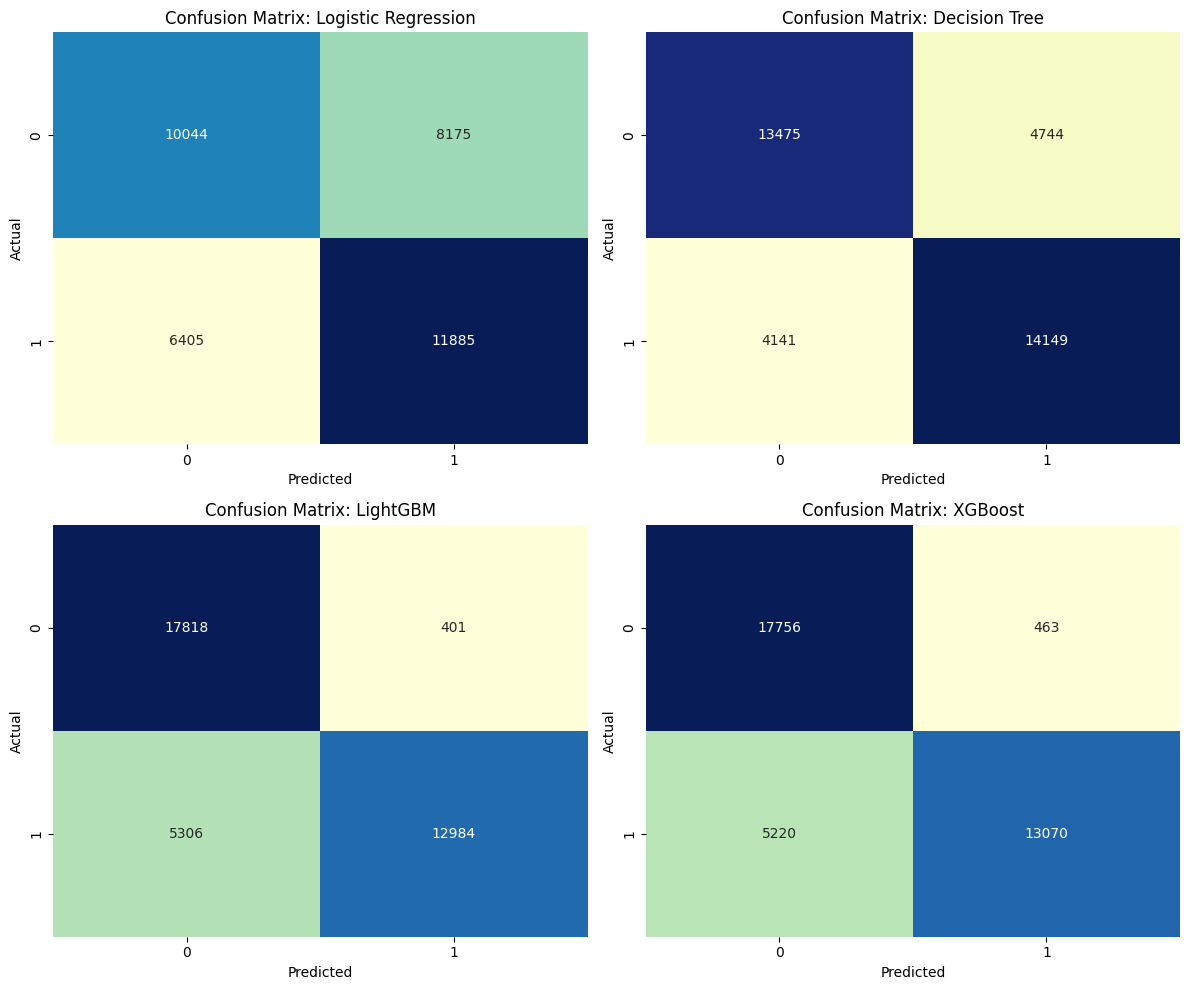

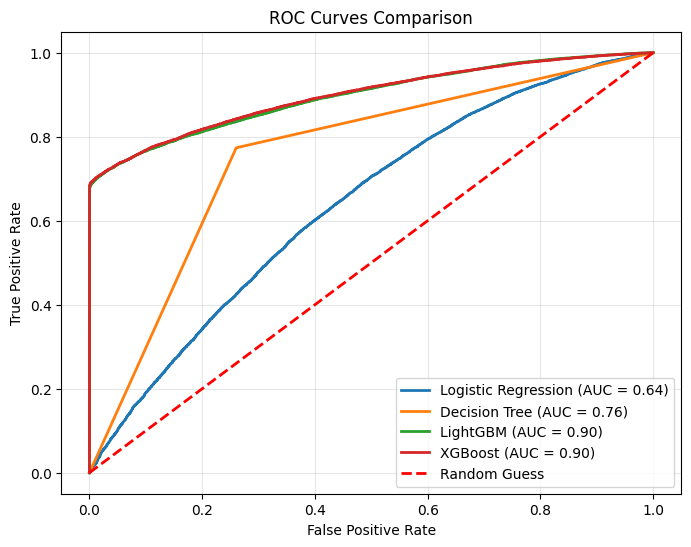

In [9]:
# Plot Confusion Matrices (Figures 1 to 4)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, (name, cm) in enumerate(cms.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu', ax=axes[idx], cbar=False)
    axes[idx].set_title(f"Confusion Matrix: {name}")
    axes[idx].set_xlabel("Predicted")
    axes[idx].set_ylabel("Actual")

plt.tight_layout()
plt.show()

# Plot ROC Curves Comparison (Figures 5 to 8)
plt.figure(figsize=(8, 6))
for name, (fpr, tpr, auc) in roc_data.items():
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc:.2f})")

plt.plot([0, 1], [0, 1], color='red', linestyle='--', lw=2, label='Random Guess')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves Comparison")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

## 5. New Addition: Fixing Data Leakage & Cost-Sensitive Threshold Optimization
**Novel Contributions:**
1. **Leak-Free Pipeline:** Splitting raw data *first* (keeping the real 21.7% default rate in the test set) and applying SMOTE *strictly* on the training data only.
2. **Cost-Sensitive Threshold Calibration:** Tuning the decision probability threshold so banks catch significantly more high-risk defaulters (boosting Recall).

In [10]:
# 1. Stratified Split FIRST (No Data Leakage!)
X_tr_clean, X_te_clean, y_tr_clean, y_te_clean = train_test_split(
    X_scaled, y, test_size=0.1, random_state=42, stratify=y
)

# 2. Apply SMOTE ONLY on Training Fold
X_tr_smote, y_tr_smote = SMOTE(random_state=42).fit_resample(X_tr_clean, y_tr_clean)

# 3. Train XGBoost & Predict Probabilities on Real Unseen Test Data
xgb_leak_free = XGBClassifier(reg_lambda=1.5, n_estimators=200, random_state=42, eval_metric='logloss')
xgb_leak_free.fit(X_tr_smote, y_tr_smote)
probs_real = xgb_leak_free.predict_proba(X_te_clean)[:, 1]

# 4. Find Optimal Cost-Sensitive Decision Threshold
best_f1, best_th = 0, 0.50
for th in np.arange(0.15, 0.55, 0.02):
    score = f1_score(y_te_clean, (probs_real >= th).astype(int))
    if score > best_f1:
        best_f1, best_th = score, th

y_pred_default = (probs_real >= 0.50).astype(int)
y_pred_tuned = (probs_real >= best_th).astype(int)

comparison = pd.DataFrame([
    {
        'Strategy': 'Leak-Free Default Threshold (0.50)',
        'Accuracy': round(accuracy_score(y_te_clean, y_pred_default), 4),
        'Precision': round(precision_score(y_te_clean, y_pred_default), 4),
        'Recall': round(recall_score(y_te_clean, y_pred_default), 4),
        'F1-Score': round(f1_score(y_te_clean, y_pred_default), 4),
        'ROC-AUC': round(roc_auc_score(y_te_clean, probs_real), 4)
    },
    {
        'Strategy': f'New Addition: Tuned Threshold ({best_th:.2f})',
        'Accuracy': round(accuracy_score(y_te_clean, y_pred_tuned), 4),
        'Precision': round(precision_score(y_te_clean, y_pred_tuned), 4),
        'Recall': round(recall_score(y_te_clean, y_pred_tuned), 4),
        'F1-Score': round(f1_score(y_te_clean, y_pred_tuned), 4),
        'ROC-AUC': round(roc_auc_score(y_te_clean, probs_real), 4)
    }
])

print("=== New Addition Results (Real-World Imbalanced Test Set) ===")
display(comparison)

=== New Addition Results (Real-World Imbalanced Test Set) ===


,Strategy,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Leak-Free Default Threshold (0.50),0.7803,0.4636,0.0767,0.1316,0.654
1,New Addition: Tuned Threshold (0.23),0.5773,0.2936,0.6740,0.4091,0.654


## 6. Interpretability: Top 15 Risk Factors Driving Vehicle Loan Default

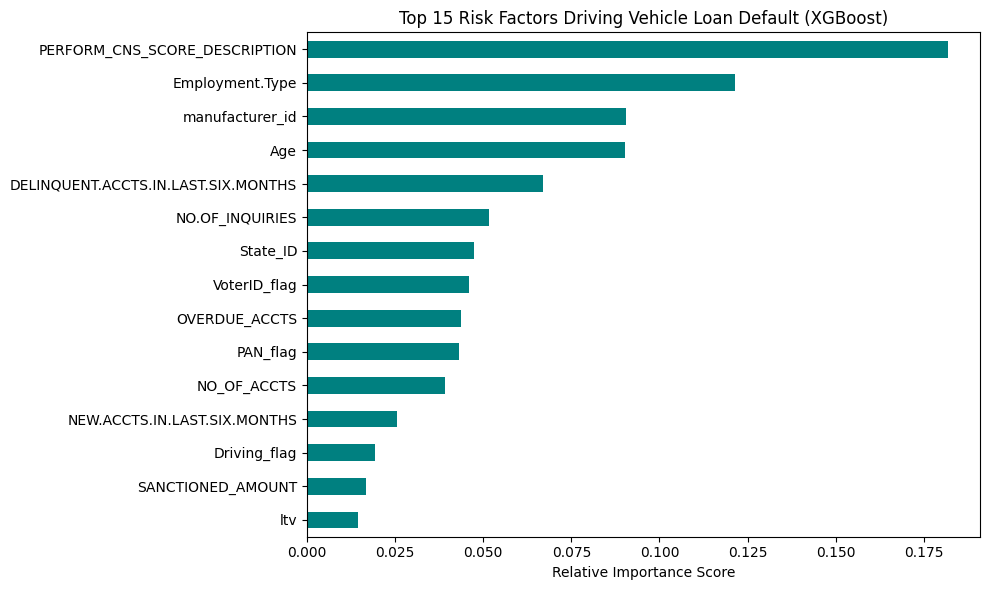

In [11]:
imp = pd.Series(xgb_leak_free.feature_importances_, index=features).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
imp.head(15).plot(kind='barh', color='teal')
plt.gca().invert_yaxis()
plt.title("Top 15 Risk Factors Driving Vehicle Loan Default (XGBoost)")
plt.xlabel("Relative Importance Score")
plt.tight_layout()
plt.show()